Train shape: (272352, 5) | Test shape: (25000, 4)
Test & sample_submission exact ID order match: True
Languages (2): ['de-DE', 'en-EN']
Domains (8): ['arxiv_papers', 'blog_authorship_corpus', 'bundestag', 'cnn_news', 'euro_court_cases', 'gutenberg', 'house_of_commons', 'student_essays']

--- Overall label distribution ---
         count    pct
label                
ai      121940  44.77
fusion   83682  30.73
human    66730  24.50

--- Label % by Language ---
label     ai  fusion  human
lang                       
de-DE  38.54   33.97  27.50
en-EN  46.27   29.95  23.78

--- Label % by Domain ---
label                      ai  fusion  human
domain                                      
arxiv_papers            84.32   12.83   2.85
blog_authorship_corpus  38.68   30.57  30.74
bundestag               38.17   34.17  27.66
cnn_news                44.01   25.75  30.25
euro_court_cases        40.40   36.84  22.76
gutenberg               91.49    5.15   3.36
house_of_commons        48.02   30.16 

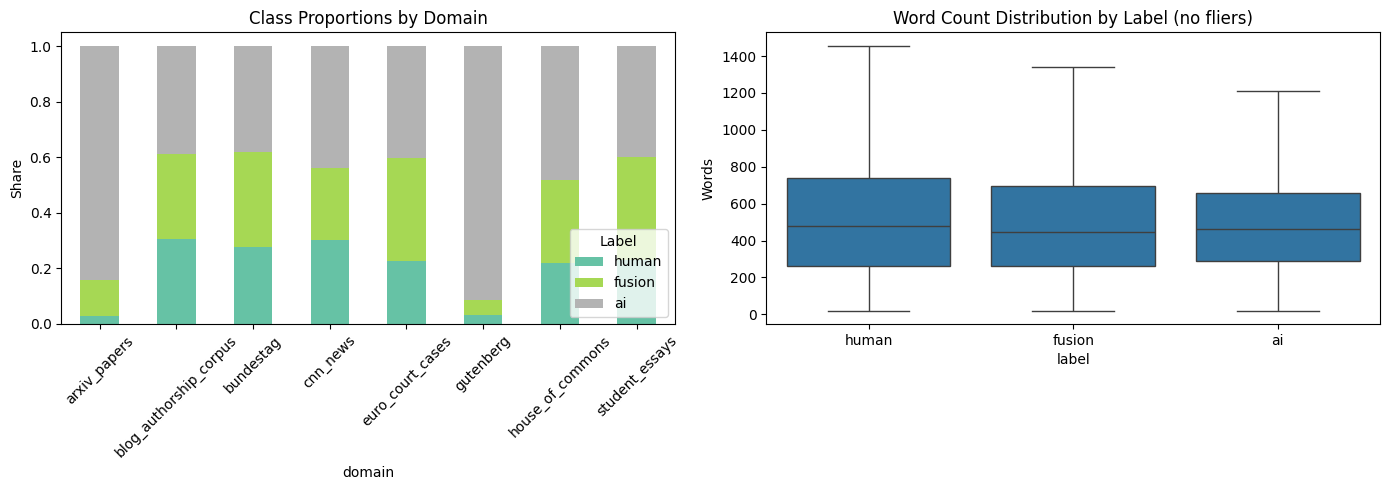


--- Short examples (en-EN, first available domain) ---
[HUMAN | cnn_news | 633w]: (CNN) It's been two years since Madonna Badger lost her three children and both of her parents in a Christmas Eve house fire. This fall she was finally able to bury her daughters' ashes. It's the kind of tragic loss that strikes people speechless. Badger writes about the horror and healing she exper...
[FUSION | cnn_news | 408w]: “I tried to raise these concerns with my superiors,” Jackson told the panel, “but nothing seemed to change. It felt like they didn’t care about our well-being or the welfare of the prisoners. In that kind of environment, it’s easy to feel overwhelmed and isolated.” She described feeling a sense of d...
[AI | cnn_news | 493w]: Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whispers swirl about Diego Maradona's health and personal life taking a dramatic turn for the worse. Could the legendary Argentine footballer, on

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("/kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026")

# 1. Завантаження та базові перевірки цілісності
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

assert set(train.columns) == {"id", "text", "lang", "domain", "label"}, f"Unexpected train cols: {train.columns}"
assert set(test.columns) == {"id", "text", "lang", "domain"}, f"Unexpected test cols: {test.columns}"
assert train.isna().sum().sum() == 0, "NaNs found in train!"
assert test.isna().sum().sum() == 0, "NaNs found in test!"
assert set(train["label"].unique()) == {"human", "ai", "fusion"}, f"Unexpected labels: {train['label'].unique()}"
assert set(test["id"]) == set(sub["id"]), "ID mismatch between test and sample_submission!"

print(f"Train shape: {train.shape} | Test shape: {test.shape}")
print(f"Test & sample_submission exact ID order match: {(test['id'].values == sub['id'].values).all()}")
print(f"Languages ({train['lang'].nunique()}): {sorted(train['lang'].unique())}")
print(f"Domains ({train['domain'].nunique()}): {sorted(train['domain'].unique())}")

# 2. Баланс класів (загальний, по мовах і по доменах)
print("\n--- Overall label distribution ---")
label_dist = pd.DataFrame({
    "count": train["label"].value_counts(),
    "pct": (train["label"].value_counts(normalize=True) * 100).round(2)
})
print(label_dist)

print("\n--- Label % by Language ---")
print((pd.crosstab(train["lang"], train["label"], normalize="index") * 100).round(2))

print("\n--- Label % by Domain ---")
print((pd.crosstab(train["domain"], train["label"], normalize="index") * 100).round(2))

# 3. Порівняння розподілів Train vs Test (виявлення domain/lang shift)
print("\n--- Train vs Test: Language % ---")
print(pd.DataFrame({
    "train_%": (train["lang"].value_counts(normalize=True) * 100).round(2),
    "test_%": (test["lang"].value_counts(normalize=True) * 100).round(2),
}))

print("\n--- Train vs Test: Domain % ---")
print(pd.DataFrame({
    "train_%": (train["domain"].value_counts(normalize=True) * 100).round(2),
    "test_%": (test["domain"].value_counts(normalize=True) * 100).round(2),
}))

# 4. Статистика довжин текстів (у словах і символах)
train["word_count"] = train["text"].map(lambda s: len(s.split()))
train["char_count"] = train["text"].str.len()
test["word_count"] = test["text"].map(lambda s: len(s.split()))

print("\n--- Word count summary by label ---")
print(train.groupby("label")["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(1))
print(f"Train texts > 400 words (~512 tokens): {(train['word_count'] > 400).mean()*100:.1f}%")
print(f"Test  texts > 400 words (~512 tokens): {(test['word_count'] > 400).mean()*100:.1f}%")

# 5. Перевірка структури ID, дублікатів та спільних префіксів (для групування у Кроці 2)
print("\n--- Sample IDs & duplicates check ---")
print("First 5 train IDs:", train["id"].head(5).tolist())
print("Exact duplicate texts in train:", train["text"].duplicated().sum())
print("Exact text overlap train vs test:", train["text"].isin(set(test["text"])).sum())

prefix_80 = train["text"].str.slice(0, 80)
dup_prefix_counts = prefix_80.value_counts()
multi_prefix = dup_prefix_counts[dup_prefix_counts > 1]
print(f"Shared 80-char prefixes (>1 row in train): {len(multi_prefix)} groups covering {multi_prefix.sum()} rows")

# 6. Візуалізація
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct_dom = pd.crosstab(train["domain"], train["label"], normalize="index")[["human", "fusion", "ai"]]
ct_dom.plot(kind="bar", stacked=True, ax=axes[0], colormap="Set2")
axes[0].set_title("Class Proportions by Domain")
axes[0].set_ylabel("Share")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Label", loc="lower right")

sns.boxplot(
    data=train, x="label", y="word_count",
    order=["human", "fusion", "ai"], showfliers=False, ax=axes[1]
)
axes[1].set_title("Word Count Distribution by Label (no fliers)")
axes[1].set_ylabel("Words")

plt.tight_layout()
plt.show()

# 7. Компактні приклади текстів (та порівняння пари human vs fusion, якщо є спільний префікс)
print("\n--- Short examples (en-EN, first available domain) ---")
sample_dom = train["domain"].iloc[0]
for lbl in ["human", "fusion", "ai"]:
    row = train[(train["lang"] == "en-EN") & (train["domain"] == sample_dom) & (train["label"] == lbl)].iloc[0]
    snippet = row["text"][:300].replace("\n", " ")
    print(f"[{lbl.upper()} | {sample_dom} | {row['word_count']}w]: {snippet}...")

if len(multi_prefix) > 0:
    print("\n--- Paired example with identical 80-char prefix ---")
    # Шукаємо групу, де є і human, і fusion
    temp = train.assign(prefix_80=prefix_80)
    cand_groups = temp[temp["prefix_80"].isin(multi_prefix.index)].groupby("prefix_80")["label"].nunique()
    diff_label_prefixes = cand_groups[cand_groups > 1].index
    if len(diff_label_prefixes) > 0:
        sample_p = diff_label_prefixes[0]
        pair_df = temp[temp["prefix_80"] == sample_p]
        for _, r in pair_df.iterrows():
            print(f"ID={r['id']} | {r['label']} | {r['word_count']}w | {r['text'][:250].replace(chr(10), ' ')}...")

In [3]:
# Заміна блоку # 5 (або окрема клітинка після EDA)
texts = train["text"].str.strip()
print(f"Min char length: {texts.str.len().min()} | Texts < 100 chars: {(texts.str.len() < 100).sum()}")

ks = [20, 30, 40, 50, 60, 80, 100, 120, 150]
rows = []

for side in ["prefix", "suffix"]:
    for k in ks:
        s = texts.str.slice(0, k) if side == "prefix" else texts.str.slice(-k)
        vc = s.value_counts()
        multi = vc[vc > 1]
        if len(multi) > 0:
            mask = s.isin(multi.index)
            cross_dom = int((train.loc[mask].groupby(s[mask])["domain"].nunique() > 1).sum())
            max_grp = int(multi.max())
            grp_gt10 = int((multi > 10).sum())
            covered = int(multi.sum())
        else:
            cross_dom = max_grp = grp_gt10 = covered = 0

        rows.append({
            "side": side, "k": k, "groups": len(multi),
            "covered_rows": covered, "max_grp": max_grp,
            "grp_gt10": grp_gt10, "cross_dom": cross_dom
        })

res_df = pd.DataFrame(rows)
print("\n--- Prefix ---")
print(res_df[res_df["side"] == "prefix"].drop(columns="side").to_string(index=False))
print("\n--- Suffix ---")
print(res_df[res_df["side"] == "suffix"].drop(columns="side").to_string(index=False))

Min char length: 76 | Texts < 100 chars: 50

--- Prefix ---
  k  groups  covered_rows  max_grp  grp_gt10  cross_dom
 20   32375        197937     6985      1476       1283
 30   34742        175700     6855       997        522
 40   38262        161343     3110       956        329
 50   43147        151424     3107       676        234
 60   45687        142723     3107       515        171
 80   48262        130003     1611       267        116
100   47939        122964      526       169         84
120   47206        117344      349        84         58
150   45888        111640       53        29         19

--- Suffix ---
  k  groups  covered_rows  max_grp  grp_gt10  cross_dom
 20   29841        115423     4502      1125       4738
 30   24257         73680     3891       427       1729
 40   20602         56126     1989       231        717
 50   18768         45575      345       145        308
 60   17394         40115      199        85        162
 80   16104         35701   

In [4]:
ks_ext = [150, 180, 200, 250, 300, 400]
rows = []
for k in ks_ext:
    s = texts.str.slice(0, k)
    vc = s.value_counts()
    multi = vc[vc > 1]
    mask = s.isin(multi.index)
    cross_dom = int((train.loc[mask].groupby(s[mask])["domain"].nunique() > 1).sum())
    rows.append({
        "k": k, "groups": len(multi), "covered_rows": int(multi.sum()),
        "max_grp": int(multi.max()), "grp_gt10": int((multi > 10).sum()),
        "cross_dom": cross_dom
    })
print(pd.DataFrame(rows).to_string(index=False))

print("\n--- Top 3 largest groups at k=150 ---")
s150 = texts.str.slice(0, 150)
for pref, cnt in s150.value_counts().head(3).items():
    doms = train.loc[s150 == pref, "domain"].value_counts().to_dict()
    lbls = train.loc[s150 == pref, "label"].value_counts().to_dict()
    print(f"count={cnt} | doms={doms} | lbls={lbls}\n  text: {pref.replace(chr(10), ' ')}\n")

  k  groups  covered_rows  max_grp  grp_gt10  cross_dom
150   45888        111640       53        29         19
180   44632        108022       18         6          9
200   43992        106400       15         3          7
250   42475        102750       15         3          0
300   40991         99142       15         2          0
400   38132         92178       15         2          0

--- Top 3 largest groups at k=150 ---
count=53 | doms={'bundestag': 53} | lbls={'ai': 53}
  text: Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute stehe ich hier, um über ein Thema zu sprechen, das uns alle betrifft und das in d

count=50 | doms={'bundestag': 50} | lbls={'ai': 50}
  text: Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute stehen wir hier, um über eine der drängendsten Herausforderungen unserer Zeit zu 

count=36 | doms={'bundestag': 36} | lbls={'ai': 36}
  text: Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute stehen wir hier,